AVAILABLE CONDUCTORS
1 - Solid Copper
2 - Solid Aluminium
3 - 7-Strand Aluminium
4 - 19-Strand Aluminium
5 - ACSR Conductor


Select conductor (1-5):  7
Invalid choice. Enter 1-5:  5
Enter conductor radius in metres:  0.025
Enter distance between phases A and B (m):  1
Enter distance between phases B and C (m):  1



TRANSMISSION LINE RESULTS
              Parameter          Value
         Conductor type ACSR Conductor
    Physical radius (m)       0.025000
                GMR (m)       0.020250
        Distance AB (m)         1.0000
        Distance BC (m)         1.0000
        Distance AC (m)         2.0000
                GMD (m)       1.259921
     Inductance (mH/km)       0.826130
Capacitance (microF/km)       0.014192


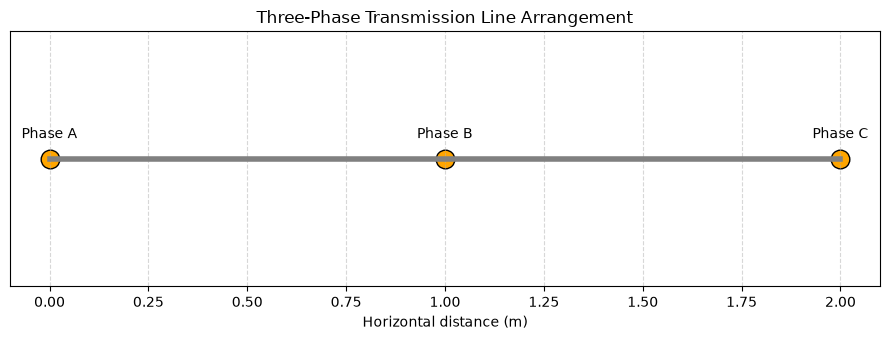

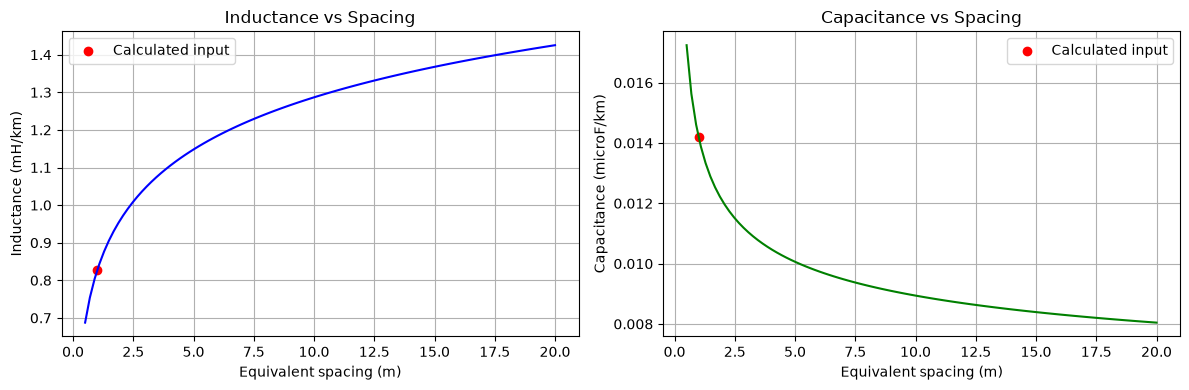


CONCLUSION
Selected conductor: ACSR Conductor
GMR = 0.020250 m
GMD = 1.259921 m
Inductance = 0.826130 mH/km
Capacitance = 0.014192 microF/km
Increasing phase spacing generally increases inductance
and decreases capacitance.


In [2]:
## import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# THREE-PHASE TRANSMISSION LINE ANALYSIS

# 1. Select conductor type
conductors = {
    "1": ("Solid Copper", 0.7788),
    "2": ("Solid Aluminium", 0.7788),
    "3": ("7-Strand Aluminium", 0.726),
    "4": ("19-Strand Aluminium", 0.758),
    "5": ("ACSR Conductor", 0.81)
}

print("AVAILABLE CONDUCTORS")
for key, value in conductors.items():
    print(key, "-", value[0])

choice = input("Select conductor (1-5): ")

while choice not in conductors:
    choice = input("Invalid choice. Enter 1-5: ")

conductor_name, factor = conductors[choice]

radius = float(input("Enter conductor radius in metres: "))

while radius <= 0:
    radius = float(input("Radius must be positive. Enter again: "))

gmr = factor * radius

# 2. Enter phase spacing
D12 = float(input("Enter distance between phases A and B (m): "))
D23 = float(input("Enter distance between phases B and C (m): "))

while D12 <= 0 or D23 <= 0:
    print("Distances must be positive.")
    D12 = float(input("Enter distance between phases A and B (m): "))
    D23 = float(input("Enter distance between phases B and C (m): "))

D13 = D12 + D23

# 3. Calculate geometric mean distance
gmd = (D12 * D23 * D13) ** (1 / 3)

if gmd <= gmr or gmd <= radius:
    raise ValueError("GMD must be greater than both GMR and radius.")

# 4. Calculate inductance and capacitance
epsilon0 = 8.854e-12

L = 2e-7 * math.log(gmd / gmr)  # H/m
C = (2 * math.pi * epsilon0) / math.log(gmd / radius)  # F/m

# 5. Display results
results = pd.DataFrame({
    "Parameter": [
        "Conductor type",
        "Physical radius (m)",
        "GMR (m)",
        "Distance AB (m)",
        "Distance BC (m)",
        "Distance AC (m)",
        "GMD (m)",
        "Inductance (mH/km)",
        "Capacitance (microF/km)"
    ],
    "Value": [
        conductor_name,
        f"{radius:.6f}",
        f"{gmr:.6f}",
        f"{D12:.4f}",
        f"{D23:.4f}",
        f"{D13:.4f}",
        f"{gmd:.6f}",
        f"{L * 1e6:.6f}",
        f"{C * 1e9:.6f}"
    ]
})

print("\nTRANSMISSION LINE RESULTS")
print(results.to_string(index=False))

# 6. Draw the conductor arrangement
x = [0, D12, D13]
y = [0, 0, 0]

plt.figure(figsize=(9, 3.5))
plt.plot([0, D13], [0, 0], color="gray", linewidth=4)
plt.scatter(x, y, s=180, color="orange", edgecolor="black")

for position, label in zip(x, ["Phase A", "Phase B", "Phase C"]):
    plt.annotate(label, (position, 0), xytext=(0, 15),
                 textcoords="offset points", ha="center")

plt.title("Three-Phase Transmission Line Arrangement")
plt.xlabel("Horizontal distance (m)")
plt.yticks([])
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 7. Investigate the effect of conductor spacing
d_equivalent = gmd / (2 ** (1 / 3))
spacing = np.linspace(0.5, 20, 100)

L_values = []
C_values = []

for d in spacing:
    gmd_d = (2 * d**3) ** (1 / 3)

    L_d = 2e-7 * math.log(gmd_d / gmr)
    C_d = (2 * math.pi * epsilon0) / math.log(gmd_d / radius)

    L_values.append(L_d * 1e6)   # mH/km
    C_values.append(C_d * 1e9)   # microF/km

# Plot both parameters
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(spacing, L_values, color="blue")
ax[0].scatter(
    [d_equivalent], [L * 1e6],
    color="red", label="Calculated input"
)
ax[0].set_title("Inductance vs Spacing")
ax[0].set_xlabel("Equivalent spacing (m)")
ax[0].set_ylabel("Inductance (mH/km)")
ax[0].grid(True)
ax[0].legend()

ax[1].plot(spacing, C_values, color="green")
ax[1].scatter(
    [d_equivalent], [C * 1e9],
    color="red", label="Calculated input"
)
ax[1].set_title("Capacitance vs Spacing")
ax[1].set_xlabel("Equivalent spacing (m)")
ax[1].set_ylabel("Capacitance (microF/km)")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()

# 8. Conclusion
print("\nCONCLUSION")
print("Selected conductor:", conductor_name)
print(f"GMR = {gmr:.6f} m")
print(f"GMD = {gmd:.6f} m")
print(f"Inductance = {L * 1e6:.6f} mH/km")
print(f"Capacitance = {C * 1e9:.6f} microF/km")
print("Increasing phase spacing generally increases inductance")
print("and decreases capacitance.")
